# 02 - Evaluation results

Loads `app/benchmark/results/*.json` (written by `app/benchmark/evaluate.py`) and compares deterministic,
LLM and hybrid modes before (v0) and after (v1) the improvements. Figures go to `docs/report/figures/`.

In [1]:
import sys, json, re
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
ROOT = HERE.parents[1] if HERE.name == "notebooks" else Path("/Users/edi/Desktop/aml-project")
sys.path.insert(0, str(ROOT / "app" / "notebooks"))
import plotstyle as ps
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

In [2]:
RES = ROOT / "app/benchmark/results"
runs = {f.stem: d for f in sorted(RES.glob("*.json")) if "configs" in (d := json.loads(f.read_text()))}
rows = []
for run, d in runs.items():
    for cfg, c in d["configs"].items():
        m = c["metrics"]
        rows.append({"run": run, "config": cfg, "mode": c["mode"], "model": c.get("model"),
                     "accuracy": m["accuracy"], "macro_f1": m["macro_f1"],
                     "gap_P": m["gap_detection"]["precision"], "gap_R": m["gap_detection"]["recall"],
                     "gap_F1": m["gap_detection"]["f1"], "false_compliance": m["false_compliance_rate"],
                     "needs_review": m["needs_review_rate"], "acc_after_deferral": m["accuracy_after_deferral"],
                     "applicability_acc": m["applicability_accuracy"], "risk_acc": m["risk_accuracy"],
                     "citation_valid": m["citation_validity"], "compliant_cited": m["compliant_with_citation"],
                     "llm_calls": m["cost"]["llm_calls_equiv"], "cost_usd": m["cost"]["cost_usd_equiv"],
                     "llm_s": m["cost"]["llm_latency_s_equiv"], "wall_s_app": m["cost"]["wall_s_per_app"]})
T = pd.DataFrame(rows)
T.style.format({c: "{:.3f}" for c in T.columns if T[c].dtype == float})

,run,config,mode,model,accuracy,macro_f1,gap_P,gap_R,gap_F1,false_compliance,needs_review,acc_after_deferral,applicability_acc,risk_acc,citation_valid,compliant_cited,llm_calls,cost_usd,llm_s,wall_s_app
0,v0_baseline,deterministic,deterministic,nan,0.794,0.723,0.781,0.877,0.826,0.123,0.054,0.840,0.987,0.800,1.000,0.913,0,0.000,0.000,0.210
1,v0_baseline,hybrid-sonnet,hybrid,sonnet,0.861,0.771,0.838,0.877,0.857,0.123,0.000,0.861,1.000,1.000,1.000,0.917,23,0.668,215.460,25.150
2,v0_baseline,llm-sonnet,llm,sonnet,0.715,0.676,0.608,1.000,0.756,0.000,0.006,0.720,1.000,1.000,1.000,1.000,170,4.814,1419.910,94.400
3,v1_improved,deterministic,deterministic,nan,0.824,0.749,0.803,0.939,0.865,0.061,0.054,0.872,1.000,1.000,1.000,0.899,0,0.000,0.000,0.190
4,v1_improved,hybrid-sonnet-all,hybrid,sonnet,0.909,0.821,0.877,0.985,0.927,0.015,0.006,0.915,1.000,1.000,1.000,1.000,170,4.817,1233.680,90.350
5,v1_improved,llm-sonnet,llm,sonnet,0.909,0.831,0.855,1.000,0.922,0.000,0.006,0.915,1.000,1.000,1.000,1.000,170,4.685,1312.650,90.930
6,v1_improved,hybrid-sonnet,hybrid,sonnet,0.946,0.866,0.969,0.969,0.969,0.031,0.006,0.951,1.000,1.000,1.000,1.000,103,2.773,749.480,0.210
7,v1_improved,hybrid-sonnet-noverifier,hybrid,sonnet,0.946,0.866,0.969,0.969,0.969,0.031,0.006,0.951,1.000,1.000,1.000,1.000,103,2.773,749.480,0.200
8,v1_improved,hybrid-haiku,hybrid,haiku,0.836,0.754,0.768,0.969,0.857,0.031,0.054,0.885,1.000,1.000,1.000,1.000,103,0.187,1005.450,74.680
9,v1_improved,llm-haiku,llm,haiku,0.715,0.667,0.619,1.000,0.765,0.000,0.073,0.771,1.000,1.000,1.000,1.000,170,0.323,1681.760,114.350


In [3]:
T.round(3)

,run,config,mode,model,accuracy,macro_f1,gap_P,gap_R,gap_F1,false_compliance,needs_review,acc_after_deferral,applicability_acc,risk_acc,citation_valid,compliant_cited,llm_calls,cost_usd,llm_s,wall_s_app
0,v0_baseline,deterministic,deterministic,NaN,0.794,0.723,0.781,0.877,0.826,0.123,0.054,0.840,0.987,0.8,1.0,0.913,0,0.000,0.00,0.21
1,v0_baseline,hybrid-sonnet,hybrid,sonnet,0.861,0.771,0.838,0.877,0.857,0.123,0.000,0.861,1.000,1.0,1.0,0.918,23,0.668,215.46,25.15
2,v0_baseline,llm-sonnet,llm,sonnet,0.715,0.676,0.608,1.000,0.756,0.000,0.006,0.720,1.000,1.0,1.0,1.000,170,4.814,1419.91,94.40
3,v1_improved,deterministic,deterministic,NaN,0.824,0.749,0.803,0.938,0.865,0.062,0.054,0.872,1.000,1.0,1.0,0.899,0,0.000,0.00,0.19
4,v1_improved,hybrid-sonnet-all,hybrid,sonnet,0.909,0.821,0.877,0.985,0.928,0.015,0.006,0.915,1.000,1.0,1.0,1.000,170,4.817,1233.68,90.35
5,v1_improved,llm-sonnet,llm,sonnet,0.909,0.831,0.855,1.000,0.922,0.000,0.006,0.915,1.000,1.0,1.0,1.000,170,4.685,1312.65,90.93
6,v1_improved,hybrid-sonnet,hybrid,sonnet,0.946,0.866,0.969,0.969,0.969,0.031,0.006,0.951,1.000,1.0,1.0,1.000,103,2.773,749.48,0.21
7,v1_improved,hybrid-sonnet-noverifier,hybrid,sonnet,0.946,0.866,0.969,0.969,0.969,0.031,0.006,0.951,1.000,1.0,1.0,1.000,103,2.773,749.48,0.20
8,v1_improved,hybrid-haiku,hybrid,haiku,0.836,0.754,0.768,0.969,0.857,0.031,0.054,0.885,1.000,1.0,1.0,1.000,103,0.187,1005.45,74.68
9,v1_improved,llm-haiku,llm,haiku,0.715,0.667,0.619,1.000,0.765,0.000,0.073,0.771,1.000,1.0,1.0,1.000,170,0.323,1681.76,114.35


## Headline comparison (v0 baseline vs v1 improved)

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


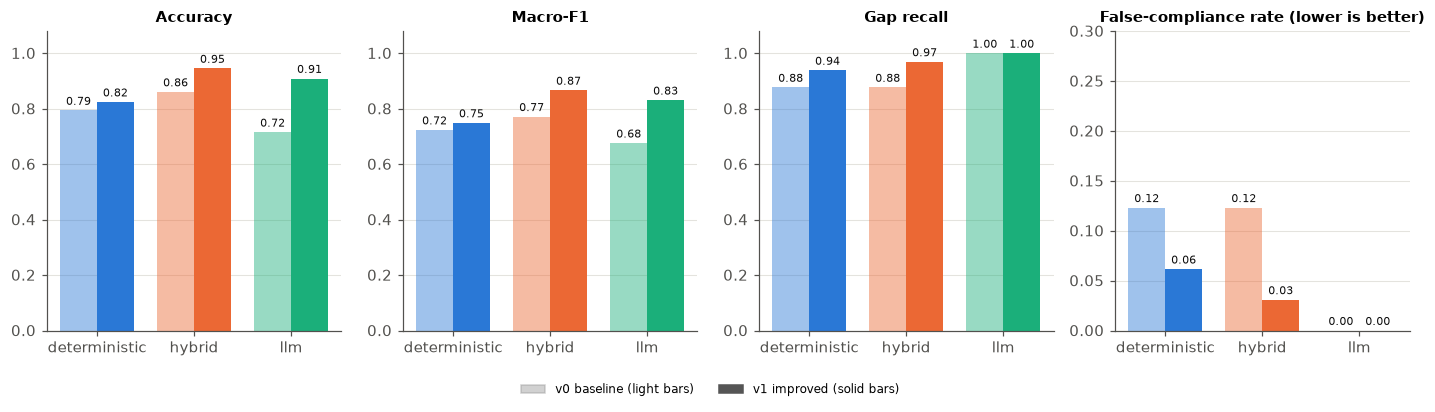

In [4]:
main = T[T.config.isin(["deterministic", "hybrid-sonnet", "llm-sonnet"])].copy()
main["label"] = main.run.str.split("_").str[0] + " " + main.config.str.replace("-sonnet", "")
metrics = [("accuracy", "Accuracy"), ("macro_f1", "Macro-F1"), ("gap_R", "Gap recall"),
           ("false_compliance", "False-compliance rate (lower is better)")]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=False)
modes = ["deterministic", "hybrid", "llm"]
x = np.arange(len(modes)); w = 0.38
for ax, (col, title) in zip(axes, metrics):
    for k, run in enumerate(sorted(main.run.unique())):
        sub = main[main.run == run].set_index("mode").reindex(modes)
        b = ax.bar(x + (k - 0.5) * w, sub[col], width=w, color=[ps.MODE_COLOR[m] for m in modes],
                   alpha=0.45 if k == 0 else 1.0, label=run)
        ps.bar_labels(ax, b, fmt="{:.2f}", fontsize=7, show_zero=True)
    ax.set_xticks(x, modes); ax.set_title(title, fontsize=9.5); ax.set_ylim(0, 1.08 if col != "false_compliance" else max(0.3, main[col].max() * 1.3))
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color="#999", alpha=0.45, label="v0 baseline (light bars)"),
                    Patch(color="#555", label="v1 improved (solid bars)")],
           loc="lower center", ncol=2, fontsize=8, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.05, 1, 1)); ps.save(fig, "results_v0_v1"); plt.show()

## Quality vs cost

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


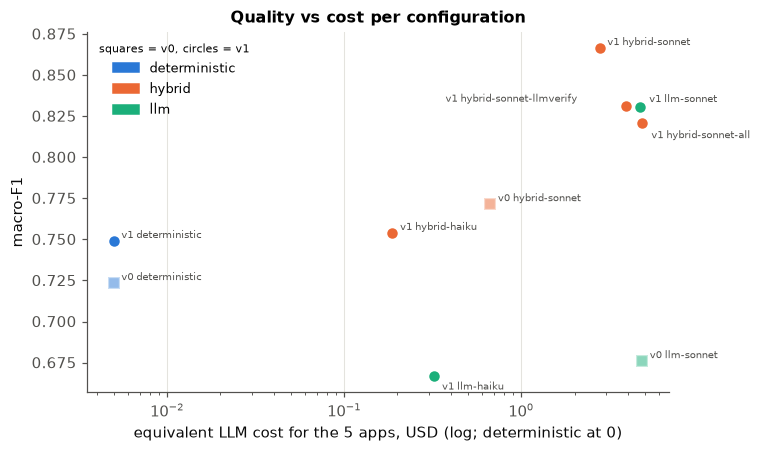

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.2))
# ablations with identical scores (no-verifier) are omitted here; see the table above
OFFSETS = {"hybrid-sonnet-llmverify": (-118, 3), "llm-sonnet": (6, 3), "hybrid-sonnet-all": (6, -10),
           "llm-haiku": (5, -9)}
for _, r in T[~T.config.str.contains("noverifier")].iterrows():
    mode = r["mode"]
    marker = "o" if r.run.startswith("v1") else "s"
    ax.scatter(max(r.cost_usd, 0.005), r.macro_f1, s=70, color=ps.MODE_COLOR[mode], marker=marker,
               edgecolor="white", linewidth=1.5, zorder=3, alpha=1 if r.run.startswith("v1") else 0.5)
    off = OFFSETS.get(r.config, (5, 2)) if r.run.startswith("v1") else (5, 2)
    ax.annotate(f"{r.run.split('_')[0]} {r.config}", (max(r.cost_usd, 0.005), r.macro_f1), fontsize=6.5,
                xytext=off, textcoords="offset points", color=ps.INK2)
ax.set_xscale("log"); ax.set_xlabel("equivalent LLM cost for the 5 apps, USD (log; deterministic at 0)")
ax.set_ylabel("macro-F1"); ax.set_title("Quality vs cost per configuration"); ax.grid(axis="both")
ax.legend(handles=[Patch(color=c, label=m) for m, c in ps.MODE_COLOR.items()], loc="upper left",
          title="squares = v0, circles = v1", title_fontsize=7)
fig.tight_layout(); ps.save(fig, "results_cost_quality"); plt.show()

## Confusion matrices (rows = ground truth, columns = prediction, all 225 labels)

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


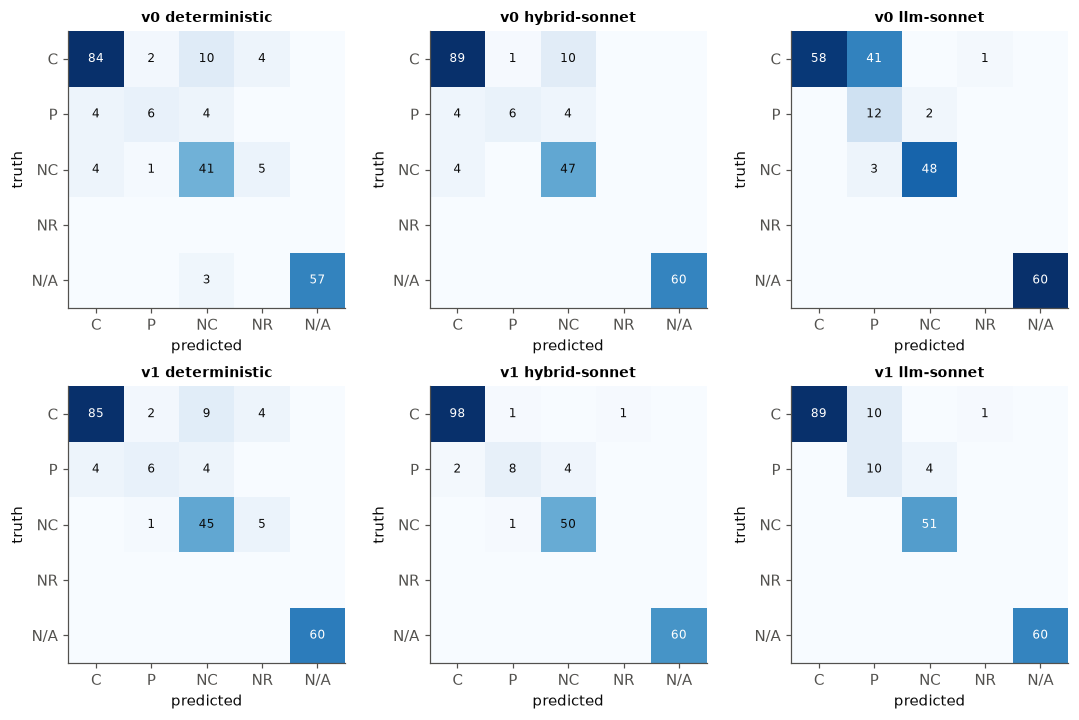

In [6]:
def plot_conf(ax, conf, title):
    S = ps.STATUS_ORDER
    M = np.array([[conf[t][p] for p in S] for t in S])
    ax.imshow(M, cmap="Blues", vmin=0, vmax=M.max())
    short = ["C", "P", "NC", "NR", "N/A"]
    ax.set_xticks(range(5), short); ax.set_yticks(range(5), short)
    for i in range(5):
        for j in range(5):
            if M[i, j]:
                ax.text(j, i, M[i, j], ha="center", va="center", fontsize=8,
                        color="white" if M[i, j] > M.max() * 0.55 else ps.INK)
    ax.set_title(title, fontsize=9); ax.grid(False)
    ax.set_xlabel("predicted"); ax.set_ylabel("truth")

cfgs = [(run, cfg) for run in sorted(runs) for cfg in ["deterministic", "hybrid-sonnet", "llm-sonnet"]
        if cfg in runs[run]["configs"]]
fig, axes = plt.subplots(2, 3, figsize=(10, 6.6))
for ax, (run, cfg) in zip(axes.flat, cfgs):
    plot_conf(ax, runs[run]["configs"][cfg]["metrics"]["confusion"], f"{run.split('_')[0]} {cfg}")
for ax in list(axes.flat)[len(cfgs):]:
    ax.axis("off")
fig.tight_layout(); ps.save(fig, "results_confusion"); plt.show()

## Per-category accuracy

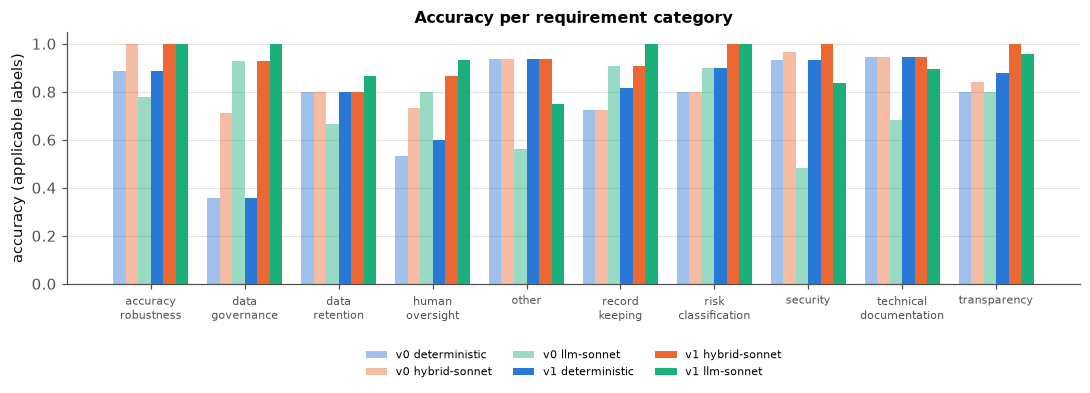

applicable labels per category:
 accuracy_robustness         9
data_governance            14
data_retention             15
human_oversight            15
other                      16
record_keeping             11
risk_classification        10
security                   31
technical_documentation    19
transparency               25


In [7]:
latest = sorted(runs)[-1]
cats = sorted({k for run in runs.values() for c in run["configs"].values() for k in c["metrics"]["per_category"]})
fig, ax = plt.subplots(figsize=(10, 3.8))
sel = [(r, c) for r in sorted(runs) for c in ["deterministic", "hybrid-sonnet", "llm-sonnet"] if c in runs[r]["configs"]]
w = 0.8 / len(sel); x = np.arange(len(cats))
for k, (r, c) in enumerate(sel):
    pc = runs[r]["configs"][c]["metrics"]["per_category"]
    vals = [pc.get(cat, {}).get("accuracy", np.nan) for cat in cats]
    mode = runs[r]["configs"][c]["mode"]
    ax.bar(x + (k - len(sel) / 2 + 0.5) * w, vals, width=w, color=ps.MODE_COLOR[mode],
           alpha=0.45 if r.startswith("v0") else 1.0, label=f"{r.split('_')[0]} {c}")
ax.set_xticks(x, [c.replace("_", "\n") for c in cats], fontsize=7.5); ax.set_ylim(0, 1.05)
ax.set_ylabel("accuracy (applicable labels)"); ax.set_title("Accuracy per requirement category")
ax.legend(ncol=3, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.22))
fig.tight_layout(); ps.save(fig, "results_per_category"); plt.show()
n = pd.Series({cat: runs[latest]["configs"]["deterministic"]["metrics"]["per_category"][cat]["n"] for cat in cats})
print("applicable labels per category:\n", n.to_string())

## Hybrid routing threshold (leave-one-app-out)

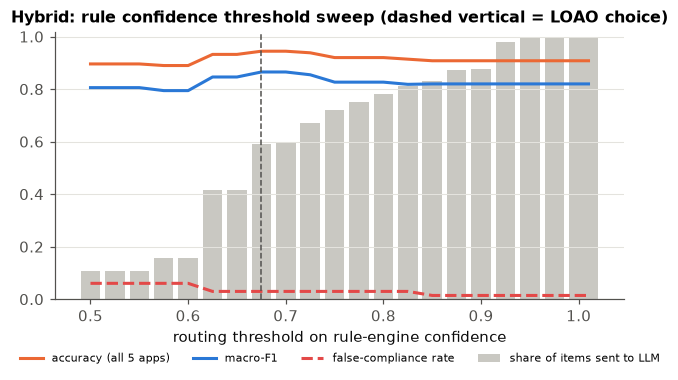

              held_out  chosen_threshold  accuracy  macro_f1  false_compliance  needs_review  llm_share   n
0          credit-lens             0.625     0.833     0.684             0.000         0.024      0.357  42
1  hireright-screening             0.675     0.976     0.884             0.000         0.000      0.452  42
2     quickhire-ranker             0.675     1.000     1.000             0.000         0.000      0.857  42
3           spamshield             0.675     0.889     0.545             0.333         0.000      0.667  18
4     supportbot-genai             0.675     0.952     0.878             0.167         0.000      0.429  21


In [8]:
sweep_file = RES / "threshold_sweep.json"
if sweep_file.exists():
    sw = json.loads(sweep_file.read_text())
    S = pd.DataFrame(sw["sweep"])
    fig, ax = plt.subplots(figsize=(6.4, 3.6))
    ax.plot(S.threshold, S.accuracy, color=ps.CAT[1], label="accuracy (all 5 apps)")
    ax.plot(S.threshold, S.macro_f1, color=ps.CAT[0], label="macro-F1")
    ax.plot(S.threshold, S.false_compliance, color=ps.CAT[7], linestyle="--", label="false-compliance rate")
    ax2 = ax.twinx() if False else None
    ax.bar(S.threshold, S.llm_share, width=0.02, color="#c9c8c2", label="share of items sent to LLM", zorder=0)
    ax.axvline(sw["chosen_threshold"], color=ps.INK2, linestyle="--", linewidth=1)
    ax.set_xlabel("routing threshold on rule-engine confidence"); ax.set_ylim(0, 1.02)
    ax.set_title("Hybrid: rule confidence threshold sweep (dashed vertical = LOAO choice)")
    ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4)
    fig.tight_layout(); ps.save(fig, "results_threshold_sweep"); plt.show()
    print(pd.DataFrame(sw["loao"]).round(3))
else:
    print("no threshold_sweep.json")

## Error analysis: remaining hybrid errors

In [9]:
cfg = "hybrid-sonnet"
items = pd.DataFrame(runs[latest]["configs"][cfg]["items"])
err = items[(items.truth != items.pred) & (items.truth != "not_applicable")]
print(f"{len(err)} errors on {(items.truth != 'not_applicable').sum()} applicable labels ({latest}, {cfg})")
print(pd.crosstab(err.truth, err.pred))
err[["app", "requirement_id", "truth", "pred", "confidence", "method"]].sort_values(["app", "requirement_id"])

9 errors on 165 applicable labels (v1_improved, hybrid-sonnet)
pred           compliant  needs_review  non_compliant  partial
truth                                                         
compliant              0             1              0        1
non_compliant          0             0              0        1
partial                2             0              4        0


,app,requirement_id,truth,pred,confidence,method
40,credit-lens,ACME-07,partial,non_compliant,0.830,hybrid
16,credit-lens,AIA-HUM-03,partial,non_compliant,0.800,hybrid
26,credit-lens,GDPR-ERA-01,partial,non_compliant,0.870,hybrid
29,credit-lens,GDPR-PBD-01,compliant,needs_review,0.500,hybrid
32,credit-lens,GDPR-ROPA-01,non_compliant,partial,0.600,hybrid
68,hireright-screening,GDPR-LAW-01,compliant,partial,0.620,hybrid
171,spamshield,ACME-03,partial,compliant,0.825,deterministic
161,spamshield,GDPR-ERA-01,partial,non_compliant,0.850,hybrid
205,supportbot-genai,GDPR-RET-01,partial,compliant,0.900,deterministic
